
# COS802: Network Analysis
## Notebook 01 — Data Exploration

### Objective
Explore the structure and characteristics of the datasets used in this research project.

### Research Question
RQ1: How do Louvain, spectral clustering, and label propagation compare in community quality, stability, and runtime?

### Dataset 1: Zachary's Karate Club
This dataset contains 34 members and 78 undirected connections.

We use this network to understand graph properties and validate our community detection methods before analysing larger networks.

### Planned Analysis
1. Load and inspect the graph.
2. Calculate basic network statistics.
3. Visualise the network.
4. Examine known community labels.
5. Identify important structural properties.


In [2]:

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

# Load Zachary's Karate Club network
G = nx.karate_club_graph()

print("Dataset: Zachary's Karate Club")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Directed:", G.is_directed())
print("Connected:", nx.is_connected(G))


Dataset: Zachary's Karate Club
Number of nodes: 34
Number of edges: 78
Directed: False
Connected: True


In [3]:

# Inspect the first 10 nodes
node_data = []

for node, attributes in G.nodes(data=True):
    node_data.append({
        "node": node,
        "club": attributes["club"],
        "degree": G.degree(node)
    })

df_nodes = pd.DataFrame(node_data)

display(df_nodes.head(10))

print("\nKnown faction sizes:")
print(df_nodes["club"].value_counts())


,node,club,degree
0,0,Mr. Hi,16
1,1,Mr. Hi,9
2,2,Mr. Hi,10
3,3,Mr. Hi,6
4,4,Mr. Hi,3
5,5,Mr. Hi,4
6,6,Mr. Hi,4
7,7,Mr. Hi,4
8,8,Mr. Hi,5
9,9,Officer,2



Known faction sizes:
club
Mr. Hi     17
Officer    17
Name: count, dtype: int64


Figure saved to: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\karate_known_factions.png


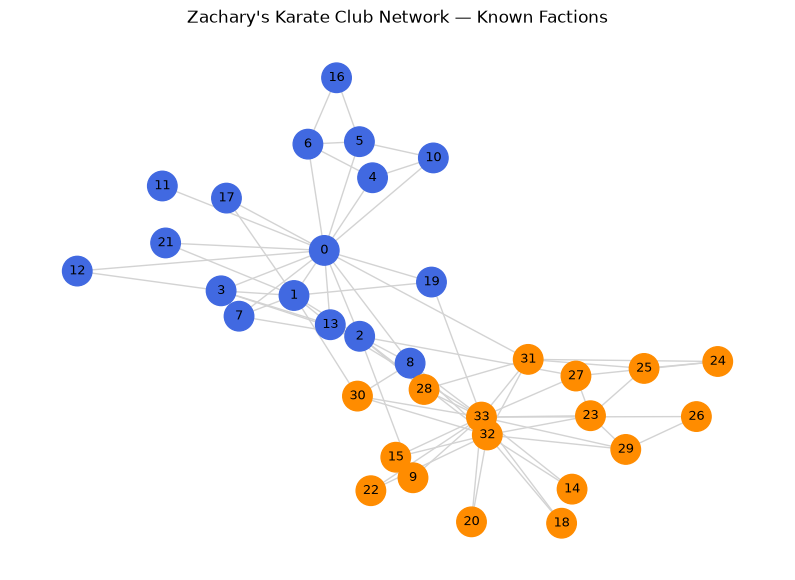

In [8]:

# Colour nodes by known faction
club_colors = {
    "Mr. Hi": "royalblue",
    "Officer": "darkorange"
}

node_colors = [
    club_colors[G.nodes[node]["club"]]
    for node in G.nodes()
]

# Fixed layout for reproducibility
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 7))

nx.draw_networkx(
    G,
    pos=pos,
    node_color=node_colors,
    with_labels=True,
    node_size=450,
    font_size=9,
    edge_color="lightgray"
)

plt.title("Zachary's Karate Club Network — Known Factions")
plt.axis("off")

from pathlib import Path

project_folder = (
    Path.home()
    / "Documents"
    / "University_Projects"
    / "cos802-network-analysis"
)

figure_path = project_folder / "figures" / "karate_known_factions.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figure saved to:", figure_path)

plt.show()



## Network Structural Analysis

We calculate network density, average degree, clustering coefficient, shortest path length, diameter and connected components to understand the structural characteristics of the Karate Club network.

These measures provide a baseline description before applying community detection algorithms.


In [5]:

import numpy as np

# Basic network statistics
n_nodes = G.number_of_nodes()
n_edges = G.number_of_edges()

density = nx.density(G)
avg_degree = sum(dict(G.degree()).values()) / n_nodes
avg_clustering = nx.average_clustering(G)
avg_shortest_path = nx.average_shortest_path_length(G)
diameter = nx.diameter(G)
n_components = nx.number_connected_components(G)

stats = {
    "Number of nodes": n_nodes,
    "Number of edges": n_edges,
    "Density": round(density, 4),
    "Average degree": round(avg_degree, 4),
    "Average clustering coefficient": round(avg_clustering, 4),
    "Average shortest path length": round(avg_shortest_path, 4),
    "Diameter": diameter,
    "Connected components": n_components
}

df_stats = pd.DataFrame(
    stats.items(),
    columns=["Metric", "Value"]
)

display(df_stats)


,Metric,Value
0,Number of nodes,34.0000
1,Number of edges,78.0000
2,Density,0.1390
3,Average degree,4.5882
4,Average clustering coefficient,0.5706
5,Average shortest path length,2.4082
6,Diameter,5.0000
7,Connected components,1.0000


In [6]:

within_edges = 0
between_edges = 0

for u, v in G.edges():
    club_u = G.nodes[u]["club"]
    club_v = G.nodes[v]["club"]

    if club_u == club_v:
        within_edges += 1
    else:
        between_edges += 1

total_edges = G.number_of_edges()

print("Within-faction edges:", within_edges)
print("Between-faction edges:", between_edges)

print(
    "Within-faction percentage:",
    round(100 * within_edges / total_edges, 2), "%"
)

print(
    "Between-faction percentage:",
    round(100 * between_edges / total_edges, 2), "%"
)


Within-faction edges: 67
Between-faction edges: 11
Within-faction percentage: 85.9 %
Between-faction percentage: 14.1 %


### Exploratory Analysis: Key Findings

The Zachary Karate Club network consists of 34 nodes and 78 undirected edges. The network is connected, meaning that a path exists between every pair of nodes.

The network has a density of 0.1390, indicating that only 13.9% of all possible connections are present. The average degree is 4.59, while the average clustering coefficient is 0.5706, suggesting that neighbouring nodes frequently form interconnected groups.

The average shortest-path length is 2.41, and the network diameter is 5, indicating that members can generally reach one another through relatively few connections.

Analysis of the known faction labels shows that 67 of the 78 edges (85.9%) connect members of the same faction, while only 11 edges (14.1%) connect members from different factions. This suggests that the network contains a meaningful group structure, with stronger connectivity within factions than between them.

These findings provide a useful starting point for evaluating community detection algorithms. The next stage will compare Louvain, spectral clustering and label propagation to determine how effectively they identify communities without using the known faction labels during detection.

In [ ]:

import subprocess
from pathlib import Path

project_folder = (
    Path.home()
    / "Documents"
    / "University_Projects"
    / "cos802-network-analysis"
)

# Check the files that have changed
result = subprocess.run(
    ["git", "status", "--short"],
    cwd=project_folder,
    capture_output=True,
    text=True
)

print(result.stdout)
